# AgriOptima: Crop yield

Predict tonnes per hectare from crop, place, season, year and area. Production is excluded to prevent target leakage. Review errors by crop; extreme yields can affect the overall result.

Run each cell in order. This notebook trains its own evaluation model and does not overwrite application artifacts.

## 1. Import libraries and find the project
Pandas reads tables; NumPy handles numbers; Matplotlib draws figures.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when Jupyter starts in the project root or this notebook folder.
ROOT = Path.cwd()
if not (ROOT / 'DataSets').exists():
    ROOT = ROOT.parent
assert (ROOT / 'DataSets').exists(), 'Open Jupyter in the project folder.'

## 2. Read, inspect and clean raw data
The source CSVs remain unchanged. Invalid rows and duplicate handling are visible below. Earlier audit records are preserved in the recovery copy outside this project.

In [2]:
raw = pd.read_csv(ROOT / 'DataSets/Yeild/crop_production_haryana_punjab_1997_2019.csv')
display(raw.head())
print('Raw rows:', len(raw))
display(raw.isna().sum())
data = raw.drop_duplicates().copy()
for column in ['State', 'District', 'Crop', 'Season']:
    data[column] = data[column].astype('string').str.strip()
for column in ['Area', 'Production', 'Yield']:
    data[column] = pd.to_numeric(data[column], errors='coerce')
data['YearStart'] = pd.to_numeric(data['Year'].astype('string').str.extract(r'((?:19|20)\d{2})', expand=False), errors='coerce')
features = ['State', 'District', 'Crop', 'Season', 'YearStart', 'Area']
valid = data[features + ['Yield']].notna().all(axis=1)
valid = valid & np.isfinite(data[['Area', 'Yield']]).all(axis=1)
valid = valid & (data['Area'] > 0) & (data['Yield'] > 0)
valid = valid & data['Area Units'].astype('string').str.lower().str.strip().isin(['hectare', 'hectares', 'ha'])
valid = valid & data['Production Units'].astype('string').str.lower().str.strip().isin(['tonne', 'tonnes', 'metric tonne', 'metric tonnes', 'metric ton', 'metric tons'])
data = data.loc[valid, features + ['Yield']].drop_duplicates().reset_index(drop=True)
data['YearStart'] = data['YearStart'].astype(int)
print('Clean rows:', len(data))
# Never include Production in X: it can directly reveal Yield.

,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield
0,Haryana,AMBALA,Arhar/Tur,2001-02,Kharif,294.0,Hectare,400.0,Tonnes,1.360544
1,Haryana,AMBALA,Arhar/Tur,2002-03,Kharif,137.0,Hectare,200.0,Tonnes,1.459854
2,Haryana,AMBALA,Arhar/Tur,2003-04,Kharif,31.0,Hectare,0.0,Tonnes,0.000000
3,Haryana,BHIWANI,Arhar/Tur,2001-02,Kharif,336.0,Hectare,200.0,Tonnes,0.595238
4,Haryana,BHIWANI,Arhar/Tur,2002-03,Kharif,1800.0,Hectare,8200.0,Tonnes,4.555556


Raw rows: 12447


State                  0
District               0
Crop                   0
Year                   0
Season                 0
Area                   0
Area Units             0
Production          1418
Production Units       0
Yield                  0
dtype: int64

Clean rows: 9882


### Look at the data
This overview describes the dataset. It is not a prediction result.

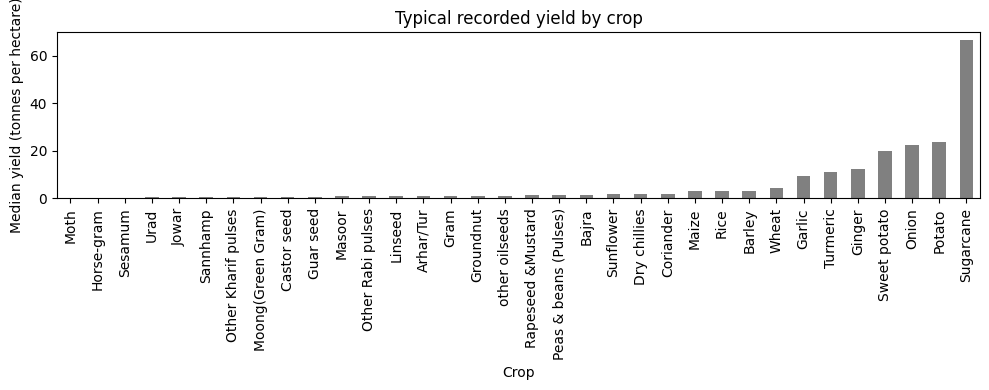

In [3]:
data.groupby('Crop')['Yield'].median().sort_values().plot.bar(figsize=(10, 4), color='gray')
plt.ylabel('Median yield (tonnes per hectare)')
plt.title('Typical recorded yield by crop')
plt.tight_layout()
plt.show()

The median is the middle recorded yield for each crop. Crops have different yield ranges, so model errors should also be checked crop by crop.

## 3. Prepare inputs, split data, train and evaluate
X contains measurements; y contains known answers in supervised tasks. Fit preprocessing on training rows only. Keep time order for prices/yield and keep soil locations together.

In [4]:

from pathlib import Path
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
text_columns = ["State", "District", "Crop", "Season"]
number_columns = ["YearStart", "Area"]
features = text_columns + number_columns

In [6]:
# 2. Learn from old years; test on later years.
train = data[data["YearStart"] < 2015]
test = data[data["YearStart"] >= 2015]
X_train = train[features]
y_train = train["Yield"]
X_test = test[features]
y_test = test["Yield"]

In [7]:
# 3. Replace missing values and convert text into numeric indicator columns.
text_steps = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)
number_steps = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
preparation = ColumnTransformer(
    [
        ("categorical", text_steps, text_columns),
        ("numerical", number_steps, number_columns),
    ]
)

### A. Make an older training period and a later validation period
Use years before 2012 to fit candidate models, 2012–2014 to choose settings, and 2015–2019 for the existing historical test. Never randomly shuffle years. The historical test has already been reported elsewhere; it is not an independent future evaluation. Production is excluded from X because it could reveal yield directly. YearStart is derived from the source’s year range; one-hot encoding represents crop, season and place.

In [8]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor

fit_rows = train[train['YearStart'] < 2012]
validation = train[train['YearStart'] >= 2012]
X_fit, y_fit = fit_rows[features], fit_rows['Yield']
X_validation, y_validation = validation[features], validation['Yield']
print('Training / validation / test:', len(fit_rows), len(validation), len(test))


Training / validation / test: 5769 1401 2712


### B. Compare regression, regularization and an ensemble
Linear Regression is the unpenalized reference. Ridge adds an L2 penalty: larger alpha shrinks coefficients more strongly. A Decision Tree shows how one tree performs. Random Forest is an ensemble: it averages trees trained on bootstrap samples with randomized feature choices. Averaging can reduce variance compared with one tree, but the measured results must justify its use.

Tune Ridge alpha; tree depth; and forest tree count, depth and minimum leaf size. Shallower trees and larger leaves limit complexity. They are tree-specific overfitting controls, not an L2 penalty. More trees generally stabilize the average but cost more computation; they do not guarantee lower error.

In [9]:
settings = [('Linear Regression', {}, LinearRegression())]
for alpha in [0.1, 1, 10, 100]:
    settings.append(('Ridge', {'alpha':alpha}, Ridge(alpha=alpha, solver='lsqr')))
for depth in [5, 10, None]:
    settings.append(('Decision Tree', {'max_depth':depth},
                     DecisionTreeRegressor(max_depth=depth, random_state=42)))
for trees in [100, 200]:
    for depth in [8, 15]:
        for leaf in [1, 3]:
            settings.append(('Random Forest', {'n_estimators':trees, 'max_depth':depth, 'min_samples_leaf':leaf},
                RandomForestRegressor(n_estimators=trees, max_depth=depth,
                    min_samples_leaf=leaf, random_state=42, n_jobs=1)))

candidates = []
for algorithm, parameters, estimator in settings:
    candidate = Pipeline([('preprocessor', clone(preparation)), ('model', estimator)])
    candidate.fit(X_fit, y_fit)
    fit_prediction = candidate.predict(X_fit)
    validation_prediction = candidate.predict(X_validation)
    candidates.append({'algorithm':algorithm, 'parameters':parameters, 'pipeline':candidate,
        'training_mae':mean_absolute_error(y_fit, fit_prediction),
        'validation_mae':mean_absolute_error(y_validation, validation_prediction),
        'validation_rmse':mean_squared_error(y_validation, validation_prediction)**0.5})
comparison = pd.DataFrame([{k:v for k,v in row.items() if k!='pipeline'} for row in candidates])
display(comparison.sort_values('validation_mae'))


,algorithm,parameters,training_mae,validation_mae,validation_rmse
3,Ridge,{'alpha': 10},2.897459e+00,3.330331,6.945955
2,Ridge,{'alpha': 1},2.890271e+00,3.375529,6.797339
1,Ridge,{'alpha': 0.1},2.889270e+00,3.499109,6.917411
0,Linear Regression,{},2.876474e+00,3.748371,7.340406
4,Ridge,{'alpha': 100},3.084974e+00,4.144802,8.865507
6,Decision Tree,{'max_depth': 10},8.493246e-01,4.953454,15.841578
7,Decision Tree,{'max_depth': None},1.587682e-19,5.029112,15.839547
5,Decision Tree,{'max_depth': 5},1.513456e+00,5.584268,16.077651
11,Random Forest,"{'n_estimators': 100, 'max_depth': 15, 'min_sa...",1.344803e+00,8.458130,45.718408
9,Random Forest,"{'n_estimators': 100, 'max_depth': 8, 'min_sam...",1.654705e+00,8.647317,45.727550


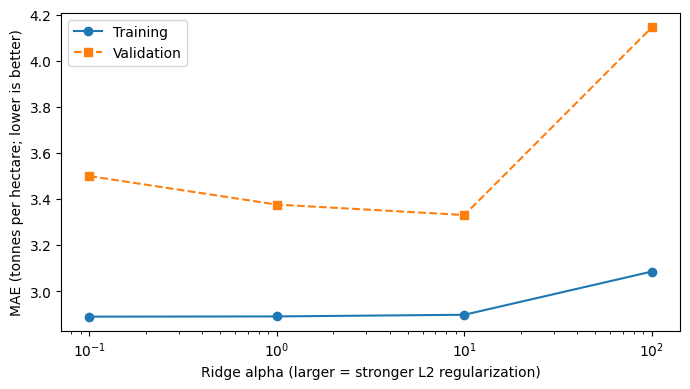

In [10]:
ridge_rows = comparison[comparison['algorithm']=='Ridge'].copy()
alpha_values = [row['alpha'] for row in ridge_rows['parameters']]
plt.figure(figsize=(7,4))
plt.plot(alpha_values, ridge_rows['training_mae'], 'o-', label='Training')
plt.plot(alpha_values, ridge_rows['validation_mae'], 's--', label='Validation')
plt.xscale('log')
plt.xlabel('Ridge alpha (larger = stronger L2 regularization)')
plt.ylabel('MAE (tonnes per hectare; lower is better)')
plt.legend()
plt.tight_layout()
plt.show()


The gap between training and validation errors helps identify overfitting. Stronger Ridge shrinkage may help or may underfit. Compare the actual validation results instead of claiming that regularization always improves performance.

### C. Freeze choices using validation, then evaluate the historical test
Choose one configuration per model family using validation MAE. Choose the overall learning model by the same validation metric. Refit each frozen family winner on all pre-2015 years, then compare against a training-median baseline on the same later test years. Test results are reporting only, not a second tuning step.

In [11]:
family_winners = []
for algorithm in ['Linear Regression', 'Ridge', 'Decision Tree', 'Random Forest']:
    options = [row for row in candidates if row['algorithm']==algorithm]
    best = options[0]
    for row in options[1:]:
        if row['validation_mae'] < best['validation_mae']:
            best = row
    family_winners.append(best)
best = family_winners[0]
for row in family_winners[1:]:
    if row['validation_mae'] < best['validation_mae']:
        best = row
selected_algorithm, selected_parameters = best['algorithm'], best['parameters']
print('Frozen learning-model choice:', selected_algorithm, selected_parameters)

baseline = np.full(len(y_test), y_train.median())
test_rows = [{'algorithm':'Training-median baseline',
    'mae':mean_absolute_error(y_test, baseline),
    'rmse':mean_squared_error(y_test, baseline)**0.5, 'r2':r2_score(y_test, baseline)}]
for row in family_winners:
    fitted = clone(row['pipeline']).fit(X_train, y_train)
    predicted = fitted.predict(X_test)
    test_rows.append({'algorithm':row['algorithm'], 'parameters':row['parameters'],
        'mae':mean_absolute_error(y_test, predicted),
        'rmse':mean_squared_error(y_test, predicted)**0.5, 'r2':r2_score(y_test, predicted)})
    if row['algorithm']==selected_algorithm:
        model = fitted
predictions = model.predict(X_test)
display(pd.DataFrame(test_rows))


Frozen learning-model choice: Ridge {'alpha': 10}


,algorithm,mae,rmse,r2,parameters
0,Training-median baseline,8.496044,20.945472,-0.161533,NaN
1,Linear Regression,3.036909,6.224388,0.897424,{}
2,Ridge,3.150330,6.397462,0.891641,{'alpha': 10}
3,Decision Tree,1.758293,4.367298,0.949502,{'max_depth': 10}
4,Random Forest,2.167760,9.778933,0.746817,"{'n_estimators': 100, 'max_depth': 15, 'min_sa..."


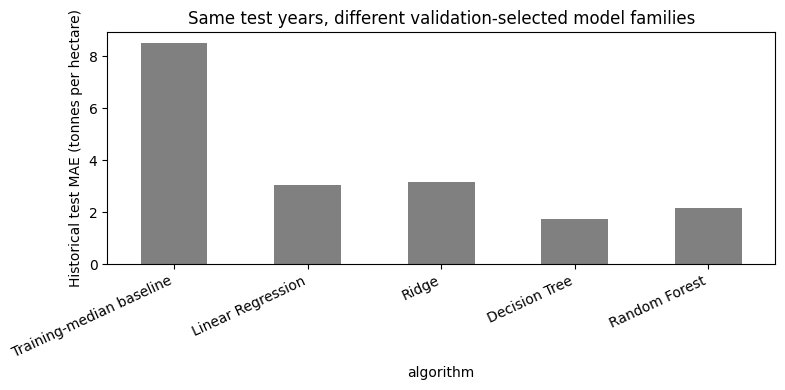

In [12]:
pd.DataFrame(test_rows).set_index('algorithm')['mae'].plot.bar(color='gray', figsize=(8,4))
plt.ylabel('Historical test MAE (tonnes per hectare)')
plt.title('Same test years, different validation-selected model families')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()


Interpret MAE as typical absolute error in t/ha, RMSE as a score more sensitive to severe errors, and R² as explained variation relative to a constant mean. Do not call R² classification accuracy. Explain any disagreement between MAE and RMSE. If the forest loses to a simpler model, report it honestly; training an ensemble does not require claiming it wins.

## 4. Figures and interpretation
These figures use held-out predictions when labels exist. For soil, they describe the held-out groups or scores.

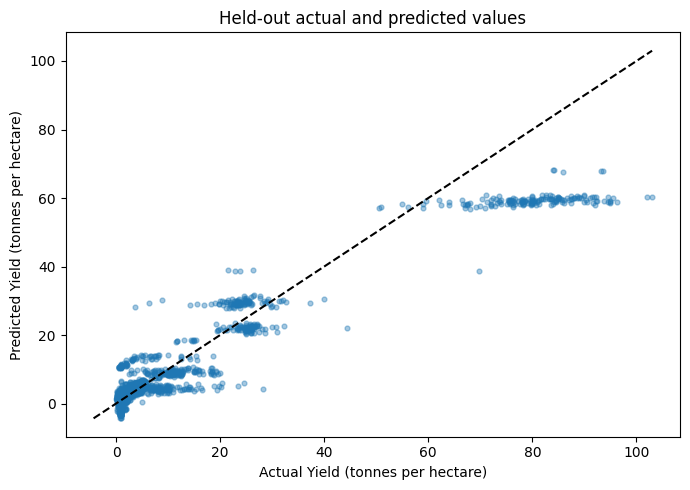

,actual,prediction
0,1.000000,0.951776
1,1.000000,0.746074
2,1.250000,1.990588
3,1.666667,0.935436
4,1.153846,0.991968


In [13]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.4, s=12)
low, high = min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], 'k--')
plt.xlabel('Actual Yield (tonnes per hectare)')
plt.ylabel('Predicted Yield (tonnes per hectare)')
plt.title('Held-out actual and predicted values')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'actual': np.asarray(y_test)[:5], 'prediction': predictions[:5]}))

The dashed line is a perfect prediction. Points away from it are errors. MAE gives their average absolute size; the table shows five held-out examples.

## 5. Save this learning model separately
The working application models remain unchanged. The saved bundle includes the features and preprocessing needed for later use. This is the holdout experiment model, not an all-data production refit.

In [14]:
import joblib
output = ROOT / 'saved_models'
output.mkdir(exist_ok=True)
bundle = {'model': model, 'features': features}
joblib.dump(bundle, output / '02_crop_yield.joblib')
print('Learning artifact saved separately.')

Learning artifact saved separately.


## 6. Viva summary and limitations
Predict tonnes per hectare from crop, place, season, year and area. Production is excluded to prevent target leakage. Review errors by crop; extreme yields can affect the overall result.

Explain: source and target, cleaning choices, split, preprocessing, algorithm, metric, baseline (if applicable), and one limitation. Fitted preprocessing must also be used for new requests. No custom Python functions or classes are defined in this notebook.

### Course checklist for this notebook
EDA and feature derivation: cleaning, crop yield distributions, YearStart and encoded categories. Regularization: explicit Ridge alpha experiment, plus depth/leaf controls for trees. Hyperparameter tuning: older training years and later validation years. Ensembles: Random Forest versus a single Decision Tree. Performance: common-period model and baseline comparisons. Classification is covered by notebook 01. The selected learning model may differ from the website’s production Random Forest; this notebook never overwrites that backend artifact.

### Read this run’s results honestly
Validation selected Ridge with alpha 10. On the reused historical test its MAE is about 3.15 t/ha, compared with 1.76 for the selected Decision Tree and 2.17 for the selected Random Forest. The Decision Tree wins this test comparison, but we do not switch the validation-selected learning model after inspecting test scores. This disagreement suggests sensitivity to the period and motivates further rolling validation or a genuinely new external test. It does not prove Ridge is universally better or that the ensemble must win. The website still uses its original separate Random Forest artifact.